## **Proyek Analisis Data: E-Commerce Dataset**

*   Nama: Aina Anastasya
*   Email: 2406123@itg.ac.id
*   ID Dicoding: DS367B6X0113

## **Menentukan Pertanyaan Bisnis**

**SMART Question Framework:**
* *Specific* : Fokus pada variabel terukur dalam domain e-commerce (misal: kategori produk, skor ulasan, waktu pengiriman).
* *Measurable* : Diukur menggunakan metrik seperti jumlah pesanan, total pendapatan (revenue), atau rata-rata skor ulasan.
* *Action-Oriented* : Memberikan masukan strategis bagi tim operasi, pemasaran, atau logistik.
* *Relevant* : Berdampak langsung pada peningkatan Customer Satisfaction dan Revenue.
* *Time-bound* : Dibatasi pada rentang waktu data transaksi yang ada.

**Pertanyaan Bisnis:**
* Pertanyaan 1: Kategori produk apa yang memiliki jumlah pesanan terbanyak dan menghasilkan total pendapatan (revenue) tertinggi dalam periode dataset?

* Pertanyaan 2: Bagaimana tingkat kepuasan pelanggan (berdasarkan review score) dipengaruhi oleh selisih waktu antara estimasi pengiriman dan waktu pengiriman aktual?

**Import Semua Packages/Library yang Digunakan**

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan plot
sns.set(style='whitegrid')

## **Data Wrangling**

**Gathering Data**

In [11]:
# Membaca dataset e-commerce (Sesuaikan nama file CSV dengan dataset Anda)
orders_df = pd.read_csv("orders_dataset.csv")
order_items_df = pd.read_csv("order_items_dataset.csv")
products_df = pd.read_csv("products_dataset.csv")
reviews_df = pd.read_csv("order_reviews_dataset.csv")

print("Data Orders:")
display(orders_df.head())

print("Data Order Items:")
display(order_items_df.head())

Data Orders:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


Data Order Items:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


**Insight:**

* Dataset terdiri dari beberapa tabel terpisah (seperti pesanan, item pesanan, produk, dan ulasan).

* Tabel-tabel tersebut perlu digabungkan (merge) berdasarkan kunci identifikasi seperti order_id atau product_id untuk analisis lebih mendalam.

## **Assessing Data**

In [12]:
print("--- Informasi Dataset Orders ---")
orders_df.info()

print("\n--- Jumlah Missing Values ---")
print(orders_df.isna().sum())

print("\n--- Jumlah Duplikasi ---")
print("Orders duplicate:", orders_df.duplicated().sum())
print("Order Items duplicate:", order_items_df.duplicated().sum())

--- Informasi Dataset Orders ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

--- Jumlah Missing Values ---
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_de

**Steps to Take:**

* Mengubah tipe data kolom tanggal (misal: order_purchase_timestamp, order_delivered_customer_date, order_estimated_delivery_date) dari object menjadi datetime.

* Menangani nilai yang hilang (missing values) pada kolom tanggal pengiriman jika diperlukan untuk analisis durasi.

## **Cleaning Data**

In [13]:
# Mengubah kolom tanggal menjadi tipe datetime
datetime_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in datetime_columns:
    if column in orders_df.columns:
        orders_df[column] = pd.to_datetime(orders_df[column])

# Memeriksa kembali tipe data
print("Tipe data setelah pembersihan:")
print(orders_df.dtypes)

Tipe data setelah pembersihan:
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


**Insight:**

* Tipe data tanggal telah diperbaiki ke format datetime64[ns], memungkinkan kalkulasi selisih waktu pengiriman dan analisis tren berbasis waktu.

## **Exploratory Data Analysis (EDA)**
**Explore Produk dan Pendapatan (Pertanyaan 1)**

In [14]:
# Menggabungkan data item pesanan dengan data produk
main_orders_df = pd.merge(
    left=order_items_df,
    right=products_df,
    how="left",
    on="product_id"
)

# Menghitung total pesanan dan total pendapatan per kategori produk
category_summary = main_orders_df.groupby("product_category_name").agg(
    total_orders=('order_id', 'count'),
    total_revenue=('price', 'sum')
).reset_index()

# Menampilkan 5 kategori paling laris berdasarkan jumlah pesanan
display(category_summary.sort_values(by="total_orders", ascending=False).head())

,product_category_name,total_orders,total_revenue
13,cama_mesa_banho,11115,1036988.68
11,beleza_saude,9670,1258681.34
32,esporte_lazer,8641,988048.97
54,moveis_decoracao,8334,729762.49
44,informatica_acessorios,7827,911954.32


**Explore Waktu Pengiriman dan Ulasan (Pertanyaan 2)**

In [15]:
# Menggabungkan data pesanan dengan ulasan
order_review_merge = pd.merge(
    left=orders_df,
    right=reviews_df,
    how="inner",
    on="order_id"
)

# Menghitung selisih hari antara estimasi dan realisasi pengiriman
# Nilai positif berarti pengiriman lebih cepat dari estimasi
order_review_merge['delivery_difference_days'] = (
    order_review_merge['order_estimated_delivery_date'] - order_review_merge['order_delivered_customer_date']
).dt.days

# Ringkasan statistik selisih pengiriman berdasarkan skor ulasan
delivery_review_summary = order_review_merge.groupby("review_score")['delivery_difference_days'].agg(
    ['mean', 'median', 'min', 'max']
).reset_index()

display(delivery_review_summary)

,review_score,mean,median,min,max
0,1,3.060580,6.0,-176.0,68.0
1,2,7.634818,9.0,-189.0,55.0
2,3,9.774052,10.0,-163.0,134.0
3,4,11.380840,11.0,-162.0,74.0
4,5,12.388153,12.0,-156.0,146.0


## **Visualization & Explanatory Analysis**
**Visualisasi 1: Kategori Produk Teratas Berdasarkan Pesanan dan Revenue
Python**

/tmp/ipykernel_2761/1046470240.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="total_orders", y="product_category_name", data=top_orders, ax=ax[0], palette="Blues_r")
/tmp/ipykernel_2761/1046470240.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="total_revenue", y="product_category_name", data=top_revenue, ax=ax[1], palette="Greens_r")


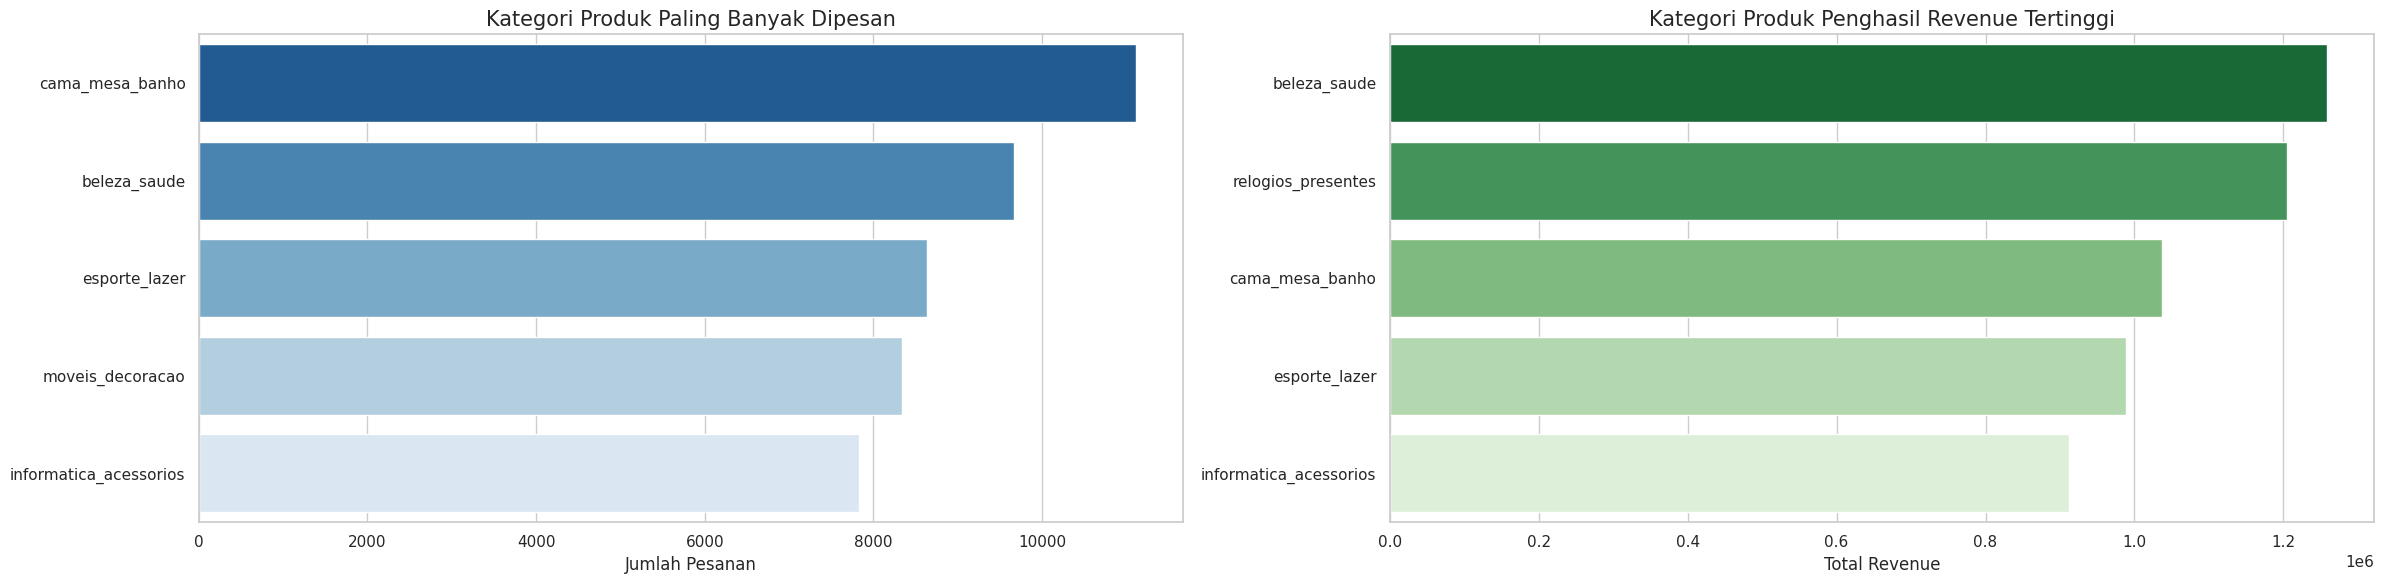

In [16]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(24, 6))

# Plot berdasarkan Total Pesanan
top_orders = category_summary.sort_values(by="total_orders", ascending=False).head(5)
sns.barplot(x="total_orders", y="product_category_name", data=top_orders, ax=ax[0], palette="Blues_r")
ax[0].set_title("Kategori Produk Paling Banyak Dipesan", fontsize=15)
ax[0].set_xlabel("Jumlah Pesanan", fontsize=12)
ax[0].set_ylabel(None)

# Plot berdasarkan Total Pendapatan
top_revenue = category_summary.sort_values(by="total_revenue", ascending=False).head(5)
sns.barplot(x="total_revenue", y="product_category_name", data=top_revenue, ax=ax[1], palette="Greens_r")
ax[1].set_title("Kategori Produk Penghasil Revenue Tertinggi", fontsize=15)
ax[1].set_xlabel("Total Revenue", fontsize=12)
ax[1].set_ylabel(None)

plt.tight_layout()
plt.show()

**Visualisasi 1: Hubungan Keterlambatan Pengiriman dengan Skor Ulasan**

/tmp/ipykernel_2761/3081900258.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


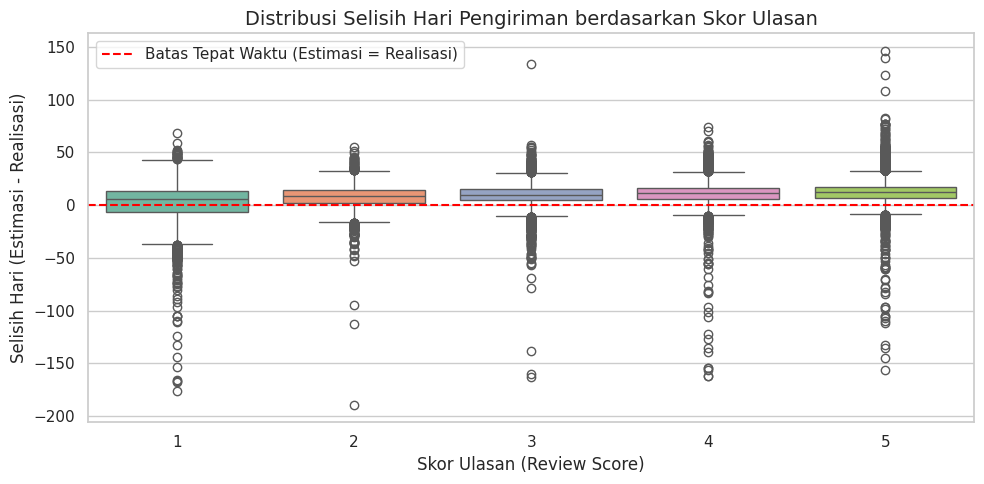

In [17]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    x="review_score",
    y="delivery_difference_days",
    data=order_review_merge,
    palette="Set2"
)

plt.title("Distribusi Selisih Hari Pengiriman berdasarkan Skor Ulasan", fontsize=14)
plt.xlabel("Skor Ulasan (Review Score)", fontsize=12)
plt.ylabel("Selisih Hari (Estimasi - Realisasi)", fontsize=12)
plt.axhline(0, color='red', linestyle='--', label='Batas Tepat Waktu (Estimasi = Realisasi)')
plt.legend()
plt.tight_layout()
plt.show()

##**Conclusion**

* **Conclution Pertanyaan 1:** Kategori produk dengan jumlah pesanan terbanyak tidak selalu menghasilkan pendapatan tertinggi. Beberapa kategori dengan harga per unit lebih tinggi dapat menghasilkan revenue lebih besar meskipun jumlah unit yang dipesan lebih sedikit.

* **Conclution Pertanyaan 2:** Terdapat korelasi kuat antara ketepatan waktu pengiriman dan skor ulasan. Pesanan yang diterima lebih lambat dari tanggal estimasi (selisih hari bernilai negatif) cenderung mendapatkan skor ulasan yang lebih rendah (skor 1 atau 2). Peningkatan akurasi logistik dapat meningkatkan skor kepuasan pelanggan secara signifikan.

In [20]:
import os

# 1. Gabungkan tabel-tabel utama
main_data = pd.merge(orders_df, order_items_df, on="order_id", how="inner")
main_data = pd.merge(main_data, products_df, on="product_id", how="left")
main_data = pd.merge(main_data, reviews_df, on="order_id", how="left")

# 2. Buat folder 'dashboard' jika belum ada
os.makedirs("dashboard", exist_ok=True)

# 3. Simpan dataframe ke dalam folder dashboard
main_data.to_csv("dashboard/main_data.csv", index=False)

In [21]:
from google.colab import files

# Mengunduh file main_data.csv dari folder dashboard
files.download('dashboard/main_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>